# Predicting High Traffic Recipe




In this notebook, our goal is to forecast recipes that are expected to achieve an 80% popularity rate while reducing the visibility of those with low popularity. We’ll start by validating the data, which involves steps like removing duplicate entries, handling missing data, and adjusting column data types in the dataframe. Next, we’ll perform exploratory data analysis to uncover meaningful patterns and trends. Based on these findings, we’ll build and evaluate a machine learning model. Finally, we’ll ensure our solution aligns with business goals and offer actionable recommendations to support the company’s success.


## Install necessary Libraries 

In [510]:
# !pip install seaborn
# !pip install LightGBM
# !pip install xgboost

## Import Libraries to be used for this project 

In [511]:
#Import neccessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import yeojohnson
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB



## Data cleaning and validation

In [512]:
#Read the csv file to start data cleaning and validation
recipe_site_traffic = pd.read_csv('recipe_site_traffic_2212.csv')
#Read the first 10 rows of our dataset
recipe_site_traffic.head(10)

,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,1,NaN,NaN,NaN,NaN,Pork,6,High
1,2,35.48,38.56,0.66,0.92,Potato,4,High
2,3,914.28,42.68,3.09,2.88,Breakfast,1,NaN
3,4,97.03,30.56,38.63,0.02,Beverages,4,High
4,5,27.05,1.85,0.80,0.53,Beverages,4,NaN
5,6,691.15,3.46,1.65,53.93,One Dish Meal,2,High
6,7,183.94,47.95,9.75,46.71,Chicken Breast,4,NaN
7,8,299.14,3.17,0.40,32.40,Lunch/Snacks,4,NaN
8,9,538.52,3.78,3.37,3.79,Pork,6,High
9,10,248.28,48.54,3.99,113.85,Chicken,2,NaN


We’ll check the dataset’s dimensions by looking at the number of rows and columns, as well as the column names and their data types. We’ll also determine how many non-null values are in each column. If we find any mismatched data types or missing values, we’ll address them as needed to ensure the dataset’s integrity.


In [514]:
#Checking the dataset's information
recipe_site_traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   recipe        947 non-null    int64  
 1   calories      895 non-null    float64
 2   carbohydrate  895 non-null    float64
 3   sugar         895 non-null    float64
 4   protein       895 non-null    float64
 5   category      947 non-null    object 
 6   servings      947 non-null    object 
 7   high_traffic  574 non-null    object 
dtypes: float64(4), int64(1), object(3)
memory usage: 59.3+ KB


## Data Cleaning

The first column to address is “category,” which is currently an object type. We need to check if any rows require changes before converting it to a categorical type. To start, we’ll examine the value distribution to better understand the data.

In [516]:
#Checking the value distribution of 'category' column
recipe_site_traffic['category'].value_counts()

category
Breakfast         106
Chicken Breast     98
Beverages          92
Lunch/Snacks       89
Potato             88
Pork               84
Vegetable          83
Dessert            83
Meat               79
Chicken            74
One Dish Meal      71
Name: count, dtype: int64

An additional category, “Chicken Breast,” appears in the “category” column. However, since the accepted categories are limited to ‘Lunch/Snacks’, ‘Beverages’, ‘Potato’, ‘Vegetable’, ‘Meat’, ‘Chicken’, ‘Pork’, ‘Dessert’, ‘Breakfast’, and ‘One Dish Meal,’ “Chicken Breast” does not fit the criteria. Therefore, it makes sense to reclassify “Chicken Breast” under the “Chicken” category. We will proceed with this adjustment.


In [518]:
#Removing "breast" from "chicken breast" value in "category" column.
recipe_site_traffic['category'] = recipe_site_traffic['category'].str.replace(' Breast', '')
#Checking "category" column to verify the if changes have been made
recipe_site_traffic['category'].value_counts()

category
Chicken          172
Breakfast        106
Beverages         92
Lunch/Snacks      89
Potato            88
Pork              84
Vegetable         83
Dessert           83
Meat              79
One Dish Meal     71
Name: count, dtype: int64

In [519]:
#Converting category column into category data type
recipe_site_traffic['category'] = recipe_site_traffic['category'].astype('category')
#Moving foward to the servings column by checking the value distribution
recipe_site_traffic['servings'].value_counts()

servings
4               389
6               197
2               183
1               175
4 as a snack      2
6 as a snack      1
Name: count, dtype: int64

Checking the 'servings' column there are some values with numeric value of 'as a snack' pharse which is not required, so we have to replace the pharse 'as a snack' with thier numeric values.

In [521]:
#Removing "as a snack" phrase with thier numerical corresponding components
recipe_site_traffic['servings'] = recipe_site_traffic['servings'].str.replace(' as a snack', '').str.strip()
#checking the servings column again
recipe_site_traffic['servings'].value_counts()


servings
4    391
6    198
2    183
1    175
Name: count, dtype: int64

Since the “servings” column consists entirely of integers, we’ll convert its data type to an integer. Although it’s numeric, it behaves more like a categorical variable. We’ll keep it as an integer for the time being, knowing that it will need to be switched back to this format when we develop and evaluate our model.


In [523]:
recipe_site_traffic['servings'] = recipe_site_traffic['servings'].astype('int64')

Given the “high_traffic” column is currently classified as an object which is our target, we need to inspect the distribution of its values. This will help us decide on the best way to convert its data type.


In [525]:
#Checking the value distribution of 'high_traffic' column
recipe_site_traffic['high_traffic'].value_counts()

high_traffic
High    574
Name: count, dtype: int64

In [526]:
#Replacing the values with 'high' as true and NaN to False
recipe_site_traffic['high_traffic'] = np.where(recipe_site_traffic['high_traffic'] == 'High', True, False)
#Rechecking the  value distribution 
recipe_site_traffic['high_traffic'].value_counts()

high_traffic
True     574
False    373
Name: count, dtype: int64

Since the “high_traffic” column only has one unique value, “High,” we’ll interpret the missing entries as representing “Low” traffic. We converted this column to a boolean data type, assigning True to “High” and False to “Low.”


In [528]:
#The next thing to do is to check for the missing value in each column
recipe_site_traffic.isna().sum()

recipe           0
calories        52
carbohydrate    52
sugar           52
protein         52
category         0
servings         0
high_traffic     0
dtype: int64

In [529]:
#Drop missing values
recipe_site_traffic = recipe_site_traffic.dropna().reset_index(drop=True)

#Rechecking missing values in columns
recipe_site_traffic.isna().sum()

recipe          0
calories        0
carbohydrate    0
sugar           0
protein         0
category        0
servings        0
high_traffic    0
dtype: int64

In [530]:
#checking the summary of dataframe's structure
recipe_site_traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 895 entries, 0 to 894
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   recipe        895 non-null    int64   
 1   calories      895 non-null    float64 
 2   carbohydrate  895 non-null    float64 
 3   sugar         895 non-null    float64 
 4   protein       895 non-null    float64 
 5   category      895 non-null    category
 6   servings      895 non-null    int64   
 7   high_traffic  895 non-null    bool    
dtypes: bool(1), category(1), float64(4), int64(2)
memory usage: 44.2 KB


## Exploratory Data Analysis

After finishing data validation and cleaning, the dataframe is ready for exploratory analysis. Next, we’ll calculate descriptive statistics for all numerical columns to gain deeper insights into the data’s characteristics.


In [532]:
recipe_site_traffic.describe()

,recipe,calories,carbohydrate,sugar,protein,servings
count,895.000000,895.000000,895.000000,895.000000,895.000000,895.000000
mean,473.652514,435.939196,35.069676,9.046547,24.149296,3.458101
std,272.763283,453.020997,43.949032,14.679176,36.369739,1.735979
min,2.000000,0.140000,0.030000,0.010000,0.000000,1.000000
25%,237.500000,110.430000,8.375000,1.690000,3.195000,2.000000
50%,475.000000,288.550000,21.480000,4.550000,10.800000,4.000000
75%,708.500000,597.650000,44.965000,9.800000,30.200000,4.000000
max,947.000000,3633.160000,530.420000,148.750000,363.360000,6.000000


Reviewing the descriptive statistics, we observe considerable variability, especially in the calories and nutrient-related columns, as reflected by the high standard deviations. The quantile values also suggest the presence of outliers, which contribute to skewed distributions. Therefore, it’s clear that the data is not normally distributed.


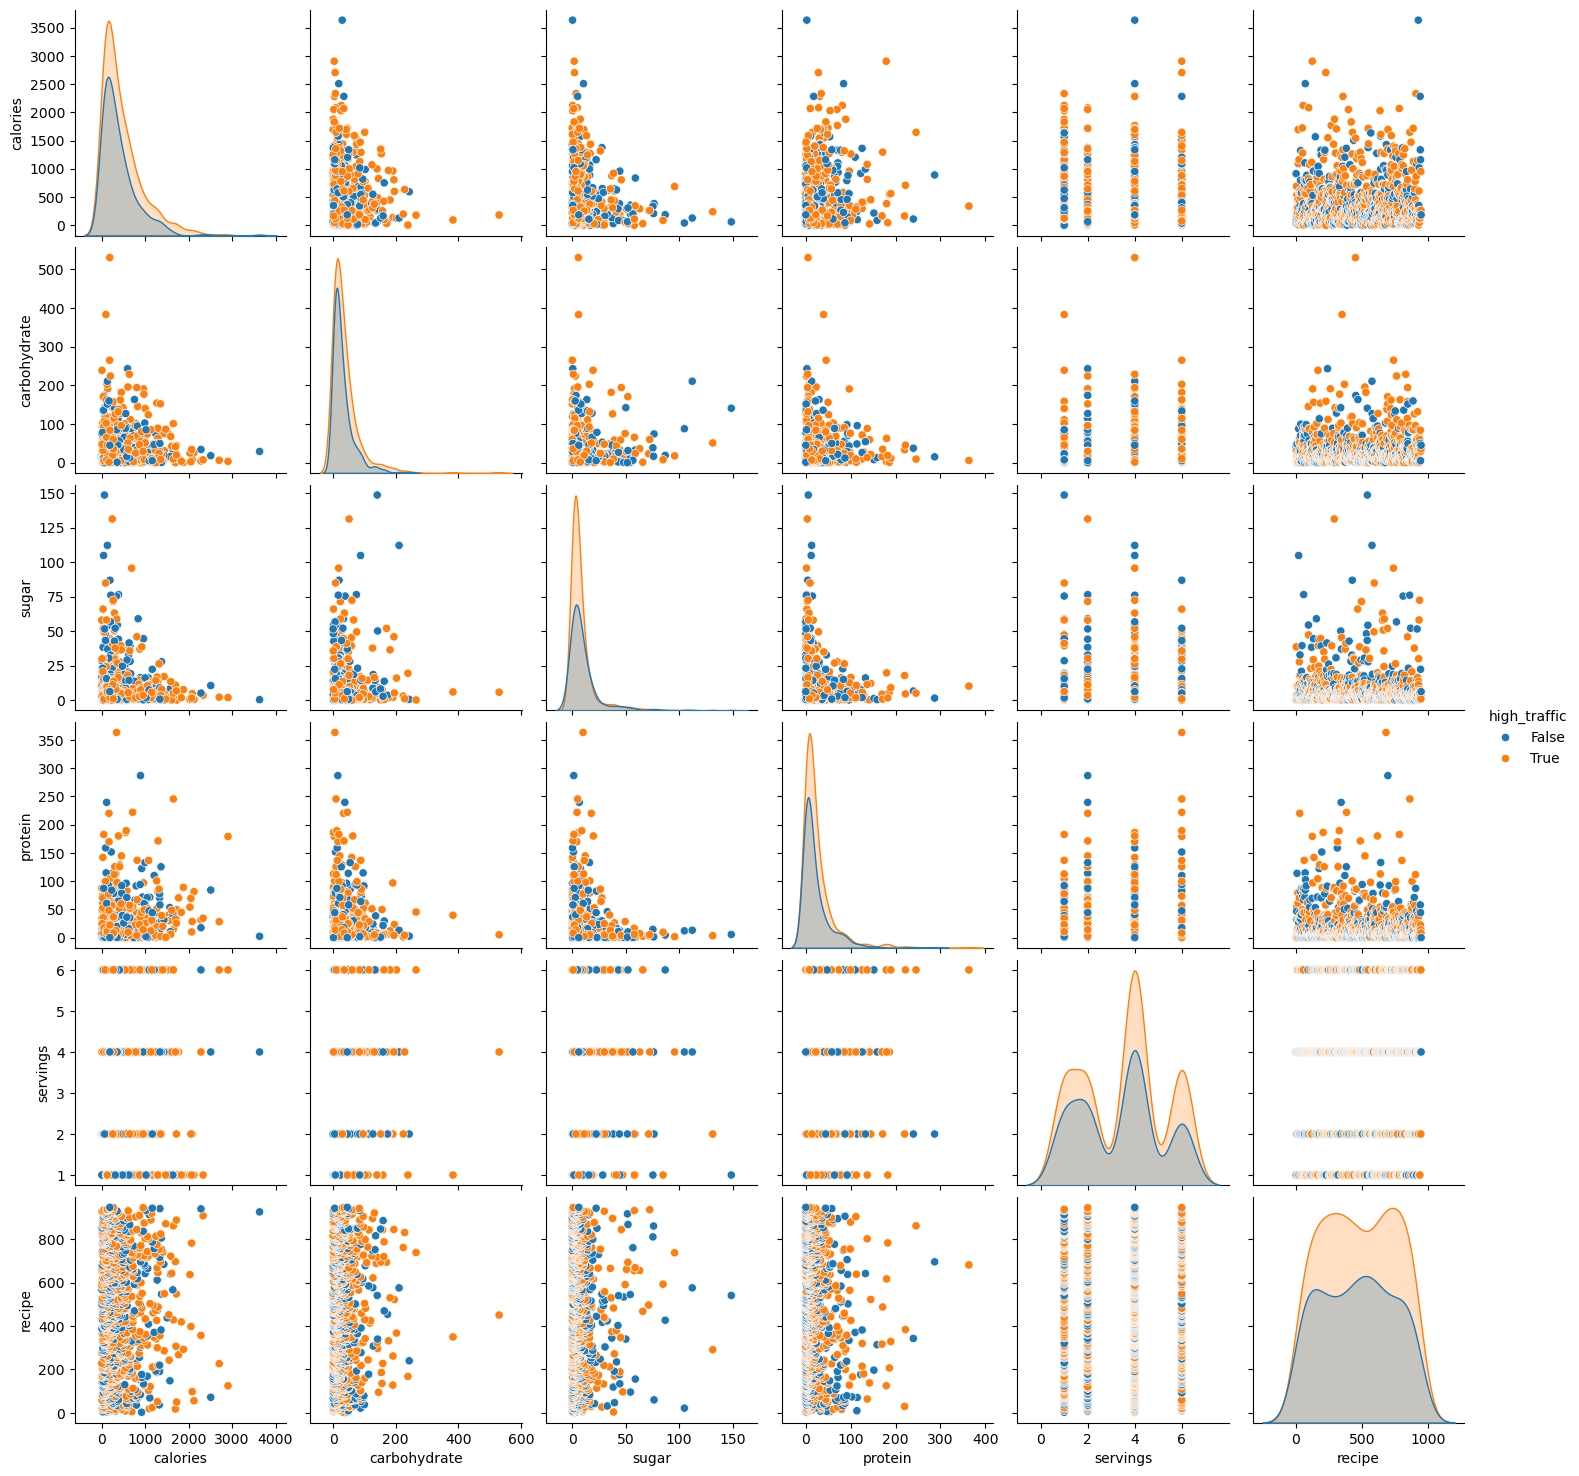

In [534]:
#Filtering columns neccesary for the analysis
filtered_column = ['calories','carbohydrate','sugar','protein','category','servings','high_traffic', 'recipe']
sns.pairplot(recipe_site_traffic[filtered_column], hue='high_traffic')
plt.show()

Based on the plot, it's apparent that there isn't a significant correlation between these columns.
Next, we'll proceed to generate a histogram to visualize the distribution of calories within the recipes.


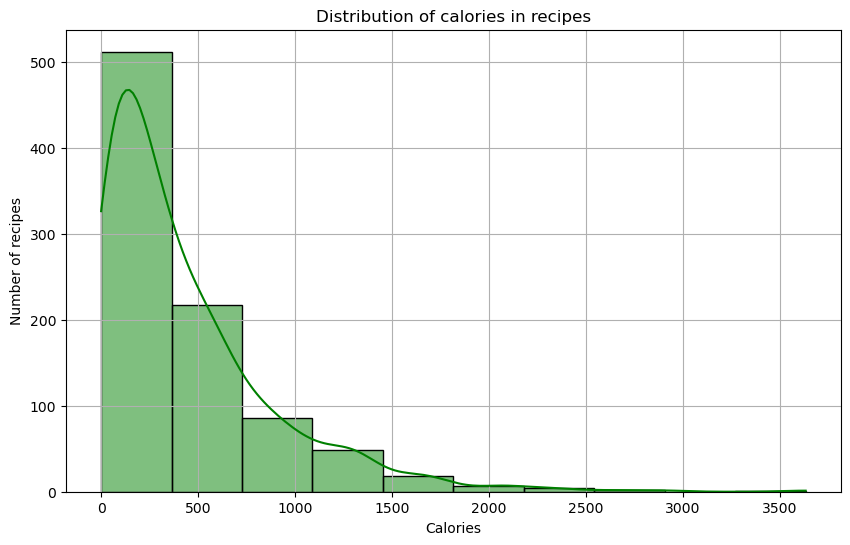

In [536]:
#Creating histogram for the distribution of calories in recipe
calories_data = recipe_site_traffic['calories']
#Set the figure size
plt.figure(figsize=(10,6))
sns.histplot(calories_data, bins=10, color='green', edgecolor='black',kde=True)
#Set x and y label
plt.xlabel("Calories")
plt.ylabel("Number of recipes")
#Set the title of the histogram
plt.title("Distribution of calories in recipes")
#set grid to true
plt.grid(True)
#Display the plot
plt.show()


The presence of Kernel Density Estimation (KDE) in the plots results in a smooth curve that illustrates the underlying data distribution.
The histogram shows most recipes have medium-calorie options available. This indicates a mix of lighter and higher-calorie recipes to suit different preferences.Proceeding to present it using box plots.


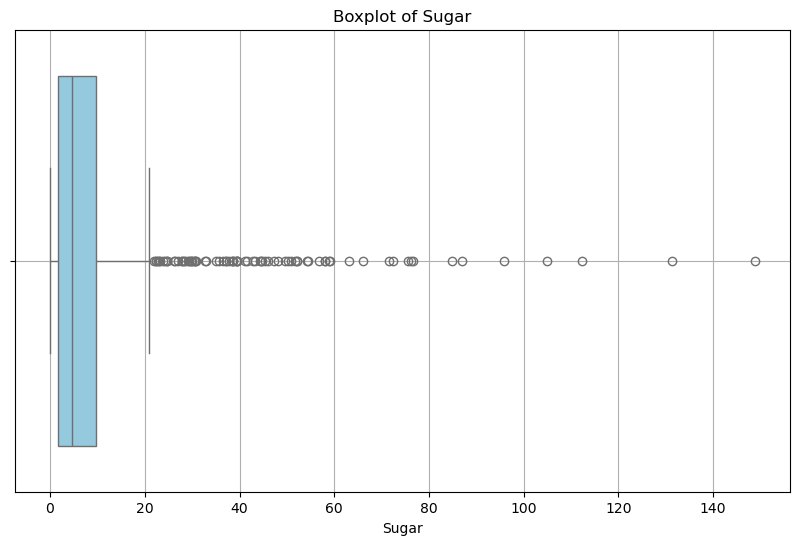

In [538]:
#Boxplot for the sugar column
#Set the figure size
plt.figure(figsize=(10,6))
sns.boxplot(recipe_site_traffic, x= 'sugar', color='skyblue')
plt.title('Boxplot of Sugar')
plt.xlabel('Sugar')
plt.grid(True)
plt.show()

Once more, the plots above affirm the existence of outliers, the right-skewed nature of these columns. 
Moving forward, let's examine the relationship between servings and high traffic status.


In [540]:
# numeric_features = recipe_site_traffic.select_dtypes(include="int").columns.tolist()

In [541]:
# plt.figure(figsize=(25,10))
# sns.heatmap(recipe_site_traffic[numeric_features].corr(),cmap = sns.diverging_palette(220, 10, as_cmap = True),annot=True, linewidths=.5, fmt= '.3f');
# plt.show()

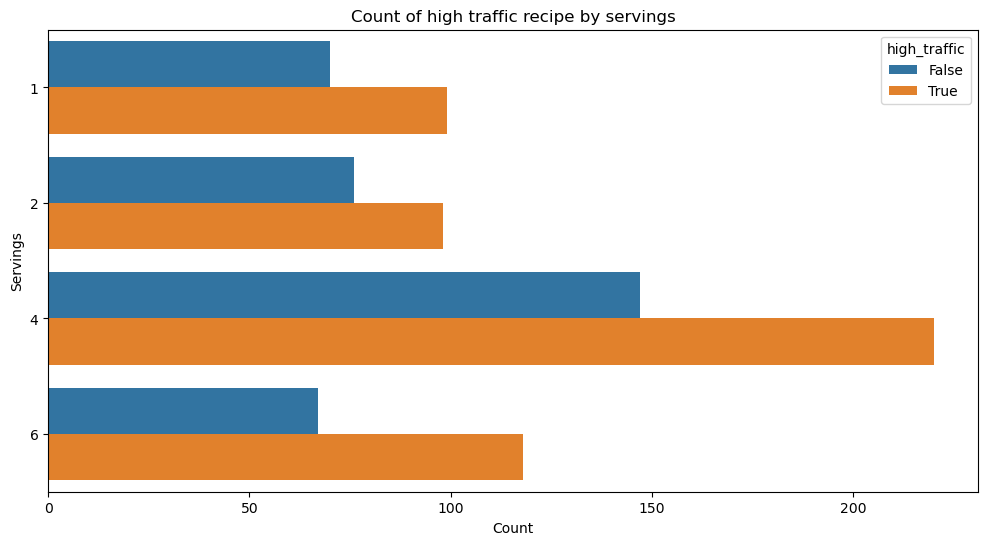

In [542]:
#Using count plot to analyse the relationship between servings and high traffc status
#Set the figure set
plt.figure(figsize=(12,6))
sns.countplot(recipe_site_traffic, y='servings', hue='high_traffic')
#Set x and y label
plt.xlabel('Count')
plt.ylabel('Servings')
#Set tittle of the countplot
plt.title('Count of high traffic recipe by servings')
plt.show()


In [543]:
#Groupby by high traffic for aggregation
high_traffic_servings = recipe_site_traffic.groupby(['servings','high_traffic']).size().unstack()
#Normalize high_traffic_servings to get the rate(ratio) to determine what servings have the highest high traffic rate
normalized_high_traffic_servings = high_traffic_servings.div(high_traffic_servings.sum(axis=1), axis=0)
print(normalized_high_traffic_servings)

high_traffic     False     True 
servings                        
1             0.414201  0.585799
2             0.436782  0.563218
4             0.400545  0.599455
6             0.362162  0.637838


Both the plot and the normalized values illustrate that recipes with 6 servings exhibit a higher rate of high traffic.
Next, we'll proceed to examine the relationship between categories and high traffic status.


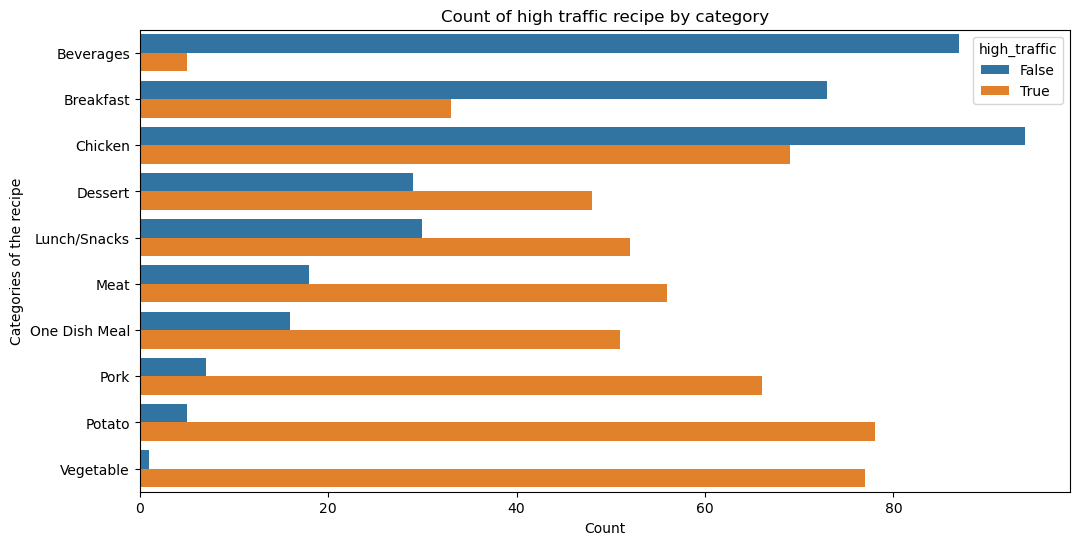

In [545]:
#Set the size of the plot
plt.figure(figsize=(12,6))
sns.countplot(recipe_site_traffic, y='category', hue='high_traffic')
#Set X and y label
plt.xlabel('Count')
plt.ylabel('Categories of the recipe')
#Set title of the countplot
plt.title('Count of high traffic recipe by category')
plt.show()


In [546]:
#Groupby by high traffic for aggregation
high_traffic_category = recipe_site_traffic.groupby(['category','high_traffic']).size().unstack()

##Normalize high_traffic_category to get the rate(ratio) to determine what Category have the highest high traffic rate
normalized_high_traffic_category = high_traffic_category.div(high_traffic_category.sum(axis=1),axis=0)
print(normalized_high_traffic_category)

high_traffic      False     True 
category                         
Beverages      0.945652  0.054348
Breakfast      0.688679  0.311321
Chicken        0.576687  0.423313
Dessert        0.376623  0.623377
Lunch/Snacks   0.365854  0.634146
Meat           0.243243  0.756757
One Dish Meal  0.238806  0.761194
Pork           0.095890  0.904110
Potato         0.060241  0.939759
Vegetable      0.012821  0.987179


C:\Users\Mariam\AppData\Local\Temp\ipykernel_11296\4231862482.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  high_traffic_category = recipe_site_traffic.groupby(['category','high_traffic']).size().unstack()



Consequently, we can deduce that showcasing recipes in certain categories leads to increased traffic.
The top three categories in terms of high traffic are "Vegetable," "Potato," and "Pork." On the other hand, the "Beverages" category appears to have the lowest traffic impact.

## Data Preparation and Preprocessing

To address this task, we will apply binary classification techniques from supervised machine learning. Several models are suitable for predicting high traffic status, including Gaussian Naïve Bayes Logistic Regression, Decision Trees, Random Forests,Support Vector Machines, Light Gradient Boosting Machine(LGBM) and Extreme Gradient Boosting(XGBoost) . For our baseline, we’ll start with Gaussian Naïve Bayes and later compare its performance with other models.

Before building the Logistic Regression model, we need to handle outliers in the dataset. We’ll do this by calculating the Interquartile Range (IQR) for each feature and using it to establish upper and lower bounds to effectively identify and manage outliers.


In [549]:
#Create a function to the lower and upper limits of column
def calculate_outlier_limits(data,factor = 1.5):
    #Calculate the 25% and 75% of the data
    q1 = np.percentile(data, 25)
    q3 = np.percentile(data, 75)
    #Calculate the iqr
    iqr = q3 - q1
    #Calculate the lower and upper limits
    lower_limit = q1 - (factor * iqr)
    upper_limit = q3 + (factor * iqr)
    return lower_limit, upper_limit

#Using the function above to calculate the outlier limits of each numerical columns
#Select numerical columns
numerical_columns = recipe_site_traffic.select_dtypes(include='float')
outlier_limits = {}
#Loop through the numerical_columns
for col in numerical_columns:
    lower_limit, upper_limit = calculate_outlier_limits(recipe_site_traffic[col])
    outlier_limits[col] = (lower_limit, upper_limit)
#Loop through outlier_limits dictionary to get the values of upper_limit and lower_limit of each numerical col
for col, limits in outlier_limits.items():
    print(f"Column: {col}")
    print(f"Lower limit {limits[0]}")
    print(f"Upper limit {limits[1]}")


Column: calories
Lower limit -620.3999999999999
Upper limit 1328.48
Column: carbohydrate
Lower limit -46.510000000000005
Upper limit 99.85000000000001
Column: sugar
Lower limit -10.475000000000003
Upper limit 21.965000000000003
Column: protein
Lower limit -37.31250000000001
Upper limit 70.70750000000001


As expected, low-value outliers are not an issue, but some high-value outliers require attention. Several methods can address this, but simply removing outliers results in excessive data loss, making it impractical. Likewise, techniques like capping or winsorization do not achieve the desired distribution.

the Yeo-Johnson transformation works best for our data.

Since some columns contain zeros, applying the Box-Cox transformation would require substituting zeros with a very small number (e.g., 0.00001), which could introduce bias. Therefore, the Yeo-Johnson method was chosen as the preferred approach.


In [551]:
#filter the dataset based on the outlier limits
transformed_data = recipe_site_traffic.copy()
for col, limits in outlier_limits.items():
    lower_limit,upper_limit = limits
    #Applying yeojohnson on the transformed data
    transformed_data[col] = yeojohnson(transformed_data[col])[0]
transformed_data.head()

,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,2,5.742712,4.409023,0.481476,0.653469,Potato,4,True
1,3,17.437753,4.550612,1.224094,1.360783,Breakfast,1,False
2,4,8.416476,4.091120,2.587146,0.019804,Beverages,4,True
3,5,5.133412,1.101661,0.553884,0.425754,Beverages,4,False
4,6,16.024489,1.607528,0.883720,4.049462,One Dish Meal,2,True


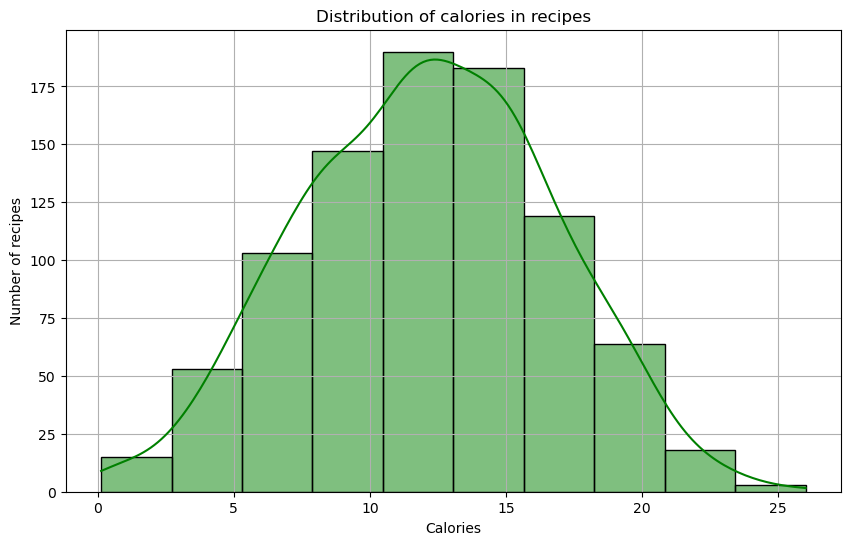

In [552]:
#Creating histogram for the distribution of calories in recipe
calories_data = transformed_data['calories']
#Set the figure size
plt.figure(figsize=(10,6))
sns.histplot(calories_data, bins=10, color='green', edgecolor='black',kde=True)
#Set x and y label
plt.xlabel("Calories")
plt.ylabel("Number of recipes")
#Set the title of the histogram
plt.title("Distribution of calories in recipes")
#set grid to true
plt.grid(True)
#Display the plot
plt.show()

Now the distribution of transformed data is normally distrubted

In [554]:
#Perform one-hot encoding on category column
encoded_category = pd.get_dummies(recipe_site_traffic['category'])
#Concatinate the encoded column with the original dataframe
recipe_site_traffic_encoded = pd.concat([transformed_data, encoded_category], axis =1)
#Drop the category column
recipe_site_traffic_encoded = recipe_site_traffic_encoded.drop('category', axis=1)
#Display the first five rows of the dataframe
recipe_site_traffic_encoded.head()

,recipe,calories,carbohydrate,sugar,protein,servings,high_traffic,Beverages,Breakfast,Chicken,Dessert,Lunch/Snacks,Meat,One Dish Meal,Pork,Potato,Vegetable
0,2,5.742712,4.409023,0.481476,0.653469,4,True,False,False,False,False,False,False,False,False,True,False
1,3,17.437753,4.550612,1.224094,1.360783,1,False,False,True,False,False,False,False,False,False,False,False
2,4,8.416476,4.091120,2.587146,0.019804,4,True,True,False,False,False,False,False,False,False,False,False
3,5,5.133412,1.101661,0.553884,0.425754,4,False,True,False,False,False,False,False,False,False,False,False
4,6,16.024489,1.607528,0.883720,4.049462,2,True,False,False,False,False,False,False,True,False,False,False


## Feature Selection and Train-Test Split

Our next steps are as follows:

First, we’ll separate the dataset into features (X) and the target variable (y), with “high_traffic” as the target. Then, using scikit-learn’s train_test_split, we’ll split the data into training and testing sets.

We’ll build the baseline model alongside other comparison models. After fitting the selected model to the training data, we’ll use it to make predictions on the test set. We’ll also use the model’s predict method on training data to check for potential overfitting.

With this plan in place, we can now proceed to develop the baseline and comparison machine learning models.


In [556]:
# Select all columns expect our target column 'high_traffic' for X
X = recipe_site_traffic_encoded.drop('high_traffic', axis= 1)
#Select our target column
y = recipe_site_traffic_encoded['high_traffic']
#Split our data to train and test data 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state=42)


## Model Evaluation

In [557]:
#Develop a function to fit, predict and calculate the model's evaluation metrics for both test and trian data
def develop_model(model, X_train, X_test, y_train, y_test, plot_cm=True ):
    evaluation_metrics = {}
    #fit the train data
    model.fit(X_train,y_train)
    #Predict train data
    model_predict_train = model.predict(X_train)
    #Predict test data
    model_predict_test = model.predict(X_test)

    #Calculating the evaluation metrics for train data (use correct argument order: y_true, y_pred)
    model_accuracy_train = accuracy_score(y_train, model_predict_train)
    model_precision_train = precision_score(y_train, model_predict_train)
    model_recall_train = recall_score(y_train, model_predict_train)
    model_f1_score_train = f1_score(y_train, model_predict_train)
    model_cm_train = confusion_matrix(y_train, model_predict_train)

    evaluation_metrics['train'] = [model_accuracy_train, model_precision_train, model_recall_train, model_f1_score_train, model_cm_train]



    #Calculating the evaluation metrics for test data (use correct argument order: y_true, y_pred)
    model_accuracy_test = accuracy_score(y_test, model_predict_test)
    model_precision_test = precision_score(y_test, model_predict_test)
    model_recall_test = recall_score(y_test, model_predict_test)
    model_f1_score_test = f1_score(y_test, model_predict_test)
    model_cm_test = confusion_matrix(y_test, model_predict_test)
     
    evaluation_metrics['test'] = [model_accuracy_test, model_precision_test, model_recall_test, model_f1_score_test, model_cm_test]
    
    # Plot beautiful confusion matrix for test data
    if plot_cm:
        plt.figure(figsize=(8, 6))
        
        # Create heatmap with customization
        sns.heatmap(model_cm_test, 
                    annot=True,           # Show numbers in cells
                    fmt='d',              # Format as integers
                    cmap='Blues',         # Color scheme (try 'YlGnBu', 'Greens', 'Purples')
                    cbar=True,            # Show color bar
                    square=True,          # Make cells square
                    linewidths=2,         # Add lines between cells
                    linecolor='white',    # Color of lines
                    annot_kws={'size': 14, 'weight': 'bold'})  # Annotation styling
        # Add labels and title
        plt.title(f'{type(model).__name__} - Test Data Confusion Matrix', 
                 fontsize=16, weight='bold', pad=20)
        plt.ylabel('Actual', fontsize=12, weight='bold')
        plt.xlabel('Predicted', fontsize=12, weight='bold')
        
        # Add labels for classes
        plt.xticks([0.5, 1.5], ['Low Traffic (0)', 'High Traffic (1)'], rotation=0)
        plt.yticks([0.5, 1.5], ['Low Traffic (0)', 'High Traffic (1)'], rotation=0)
        
        plt.tight_layout()
        plt.show()
  
    return evaluation_metrics

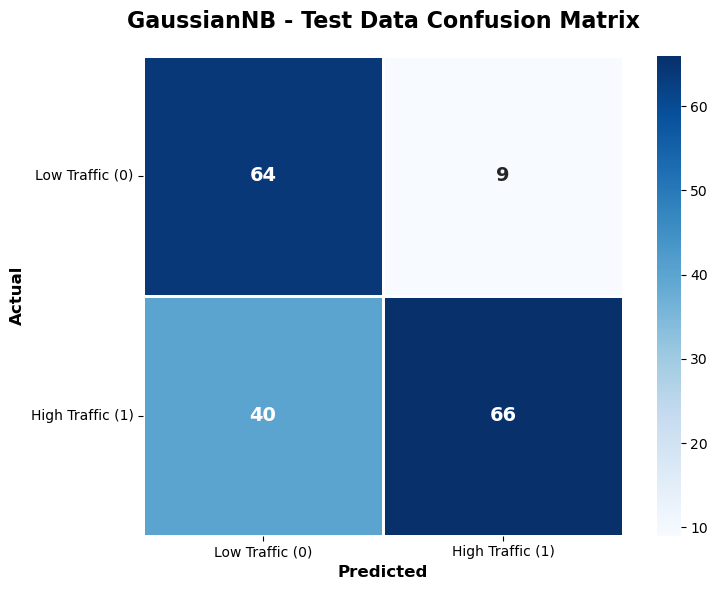

In [558]:
#Instantiate the Gussian Naive Bayes Model
gnb = GaussianNB()
#Apply the function "develop_model" to get  Gussian Bayes evaluation metrics
gnb_evaluation_metrics = develop_model(gnb, X_train,X_test, y_train, y_test)


c:\Users\Mariam\anaconda3\envs\Python__Ds\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


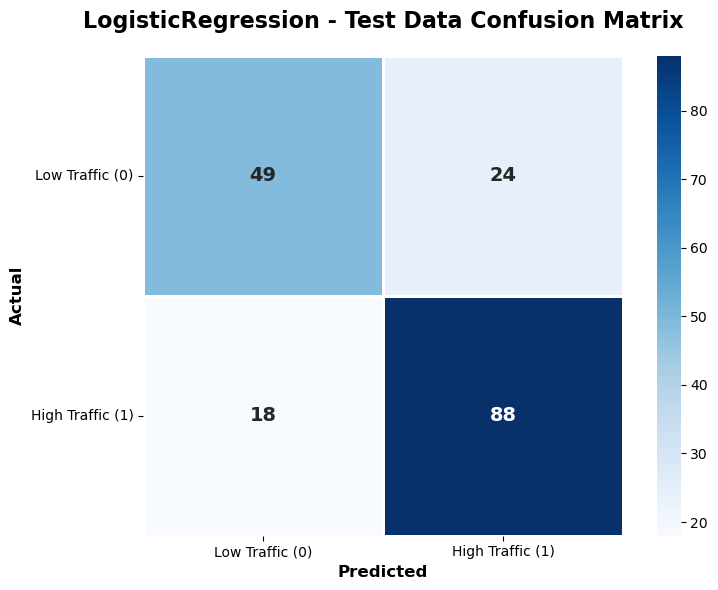

In [559]:
#Instanstiate LogisticRegression
logreg = LogisticRegression()
#Apply the function 'develop_model' to get logisticRegression evaluation metrics
logreg_evaluation_metrics = develop_model(logreg, X_train, X_test, y_train, y_test)



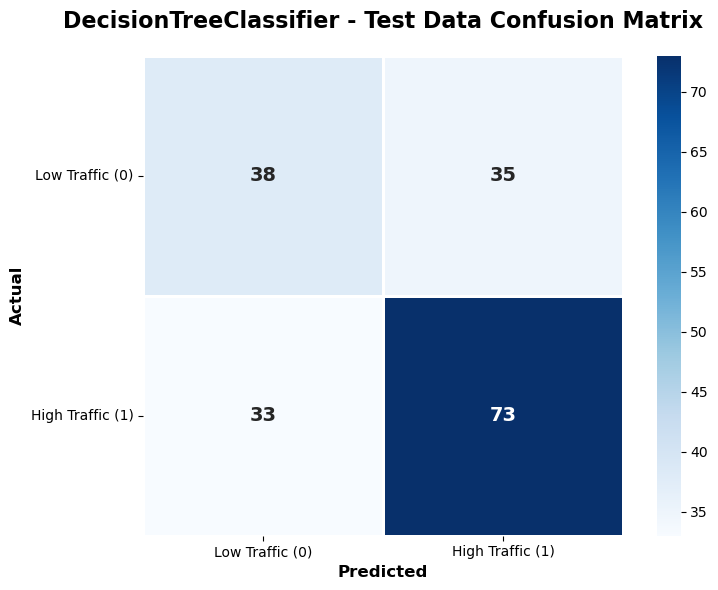

In [560]:

#Instanstiate DecisionTreeClassifier
ds = DecisionTreeClassifier()
#Apply the function 'develop_model' to get DecisionTreeClassifier evaluation metrics
ds_evaluation_metrics = develop_model(ds, X_train, X_test, y_train, y_test)



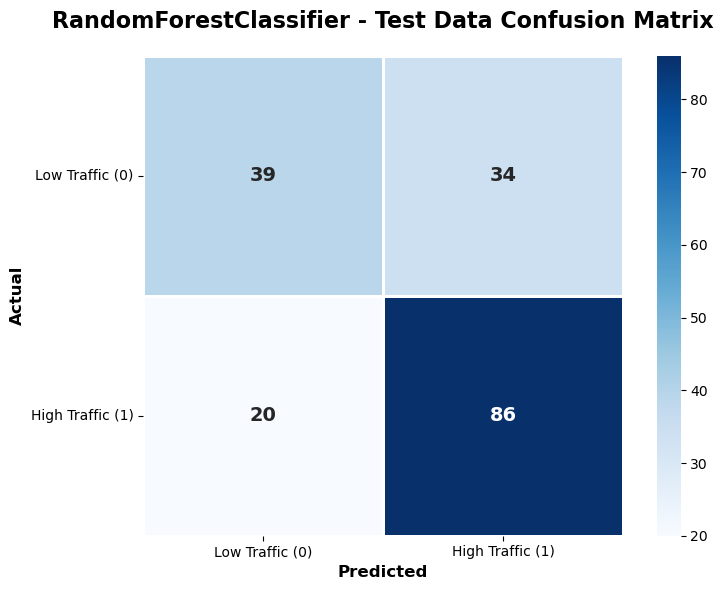

In [561]:
#Instanstiate LogisticRegression
rf = RandomForestClassifier()
#Apply the function 'develop_model' to get RandomForestClassifier evaluation metrics
rf_evaluation_metrics = develop_model(rf, X_train, X_test, y_train, y_test)


In [562]:
# Feature Importance Analysis Function
def analyze_feature_importance(model, X_train, feature_names, model_name, top_n=10):

    
    # Extract feature importance based on model type
    if hasattr(model, 'coef_'):  # Logistic Regression
        # Get absolute values of coefficients
        importance = np.abs(model.coef_[0])
        importance_type = 'Coefficient Magnitude'
        
    elif hasattr(model, 'feature_importances_'):  # Random Forest, Decision Tree, etc.
        importance = model.feature_importances_
        importance_type = 'Gini Importance'
        
    else:
        print(f"Model {model_name} does not support feature importance extraction.")
        return None
    
    # Create DataFrame
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importance
    })
    
    # Sort by importance
    importance_df = importance_df.sort_values('Importance', ascending=False).reset_index(drop=True)
    
    # Display top N features
    print(f"\n{'='*60}")
    print(f"{model_name} - Top {top_n} Most Important Features")
    print(f"Importance Type: {importance_type}")
    print(f"{'='*60}")
    print(importance_df.head(top_n).to_string(index=False))
    print(f"{'='*60}\n")
    
    # Visualization
    plt.figure(figsize=(10, 6))
    
    # Plot top N features
    top_features = importance_df.head(top_n)
    
    # Create horizontal bar plot
    colors = plt.cm.viridis(np.linspace(0.3, 0.9, top_n))
    bars = plt.barh(range(len(top_features)), top_features['Importance'], color=colors)
    
    # Customize plot
    plt.yticks(range(len(top_features)), top_features['Feature'])
    plt.xlabel('Importance Score', fontsize=12, weight='bold')
    plt.ylabel('Features', fontsize=12, weight='bold')
    plt.title(f'{model_name} - Feature Importance ({importance_type})', 
              fontsize=14, weight='bold', pad=20)
    
    # Add value labels on bars
    for i, (bar, value) in enumerate(zip(bars, top_features['Importance'])):
        plt.text(value, i, f' {value:.4f}', 
                va='center', fontsize=9, weight='bold')
    
    # Invert y-axis so highest importance is at top
    plt.gca().invert_yaxis()
    
    plt.grid(axis='x', alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()
    
    return importance_df





FEATURE IMPORTANCE ANALYSIS

--------------------------------------------------------------------------------
LOGISTIC REGRESSION - COEFFICIENT ANALYSIS
--------------------------------------------------------------------------------

Logistic Regression - Top 15 Most Important Features
Importance Type: Coefficient Magnitude
      Feature  Importance
    Beverages    2.014048
    Breakfast    1.537335
    Vegetable    1.442506
      Chicken    1.193319
       Potato    1.166447
         Pork    0.843980
        sugar    0.494877
         Meat    0.376004
One Dish Meal    0.340617
      Dessert    0.220694
 carbohydrate    0.201411
      protein    0.184631
 Lunch/Snacks    0.063833
     servings    0.056575
     calories    0.024070



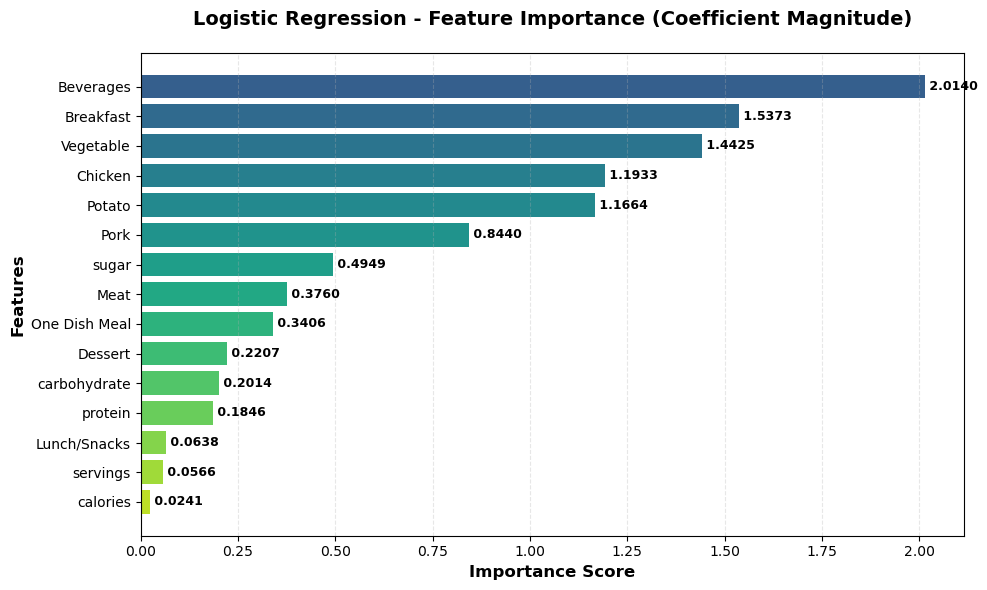


--------------------------------------------------------------------------------
RANDOM FOREST - GINI IMPORTANCE ANALYSIS
--------------------------------------------------------------------------------

Random Forest - Top 15 Most Important Features
Importance Type: Gini Importance
     Feature  Importance
     protein    0.146474
    calories    0.125781
       sugar    0.124779
carbohydrate    0.120881
   Beverages    0.117615
      recipe    0.113657
   Breakfast    0.063132
    servings    0.045013
   Vegetable    0.036566
     Chicken    0.029588
      Potato    0.022839
        Pork    0.018249
        Meat    0.009230
Lunch/Snacks    0.009189
     Dessert    0.008949



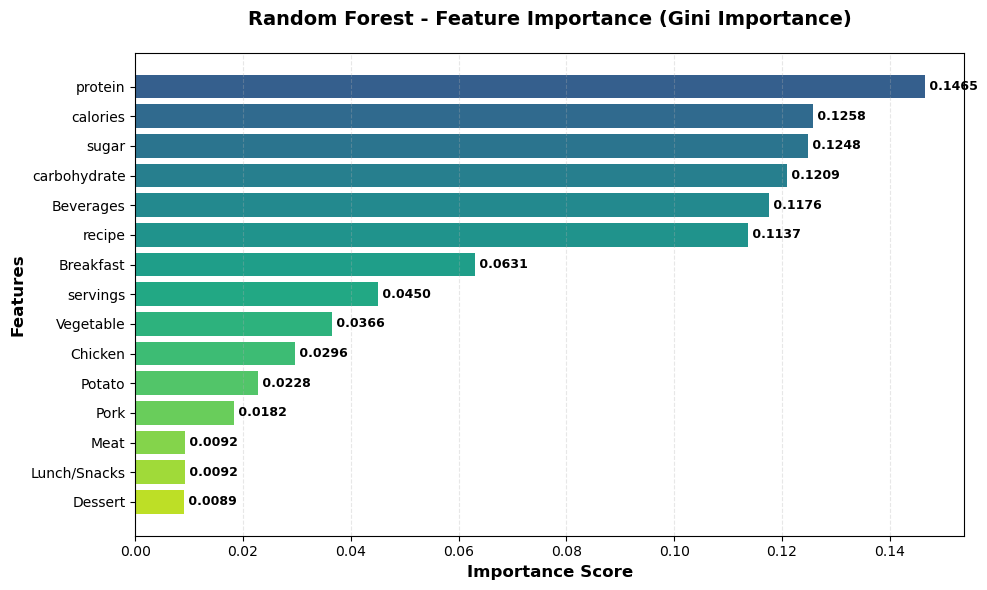

In [ ]:

print("\n" + "="*80)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*80)


feature_names = X_train.columns.tolist()  


# Analyze Logistic Regression
print("\n" + "-"*80)
print("LOGISTIC REGRESSION - COEFFICIENT ANALYSIS")
print("-"*80)
lr_importance = analyze_feature_importance(
    model=logreg,  
    X_train=X_train,
    feature_names=feature_names,
    model_name='Logistic Regression',
    top_n=15  
)


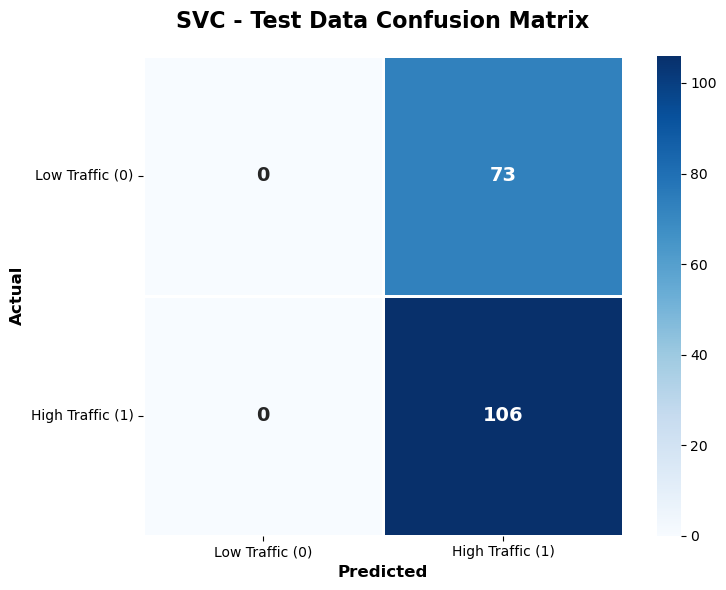

In [564]:
#Instanstiate LogisticRegression
svm = SVC()
#Apply the function 'develop_model' to get Support Vector Machine evaluation metrics
svm_evaluation_metrics = develop_model(svm, X_train, X_test, y_train, y_test)


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 429, number of negative: 287
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.033885 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1220
[LightGBM] [Info] Number of data points in the train set: 716, number of used features: 16
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.599162 -> initscore=0.401975
[LightGBM] [Info] Start training from score 0.401975
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: 

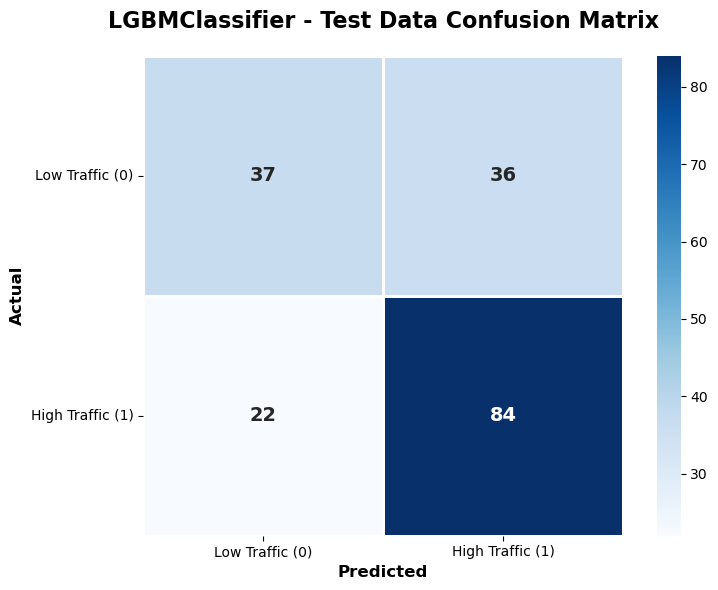

In [565]:
#Instanstiate LogisticRegression
lgmb= LGBMClassifier()
#Apply the function 'develop_model' to get Light Gradient Boosting Machine evaluation metrics

lgmb_evaluation_metrics = develop_model(lgmb, X_train, X_test, y_train, y_test)


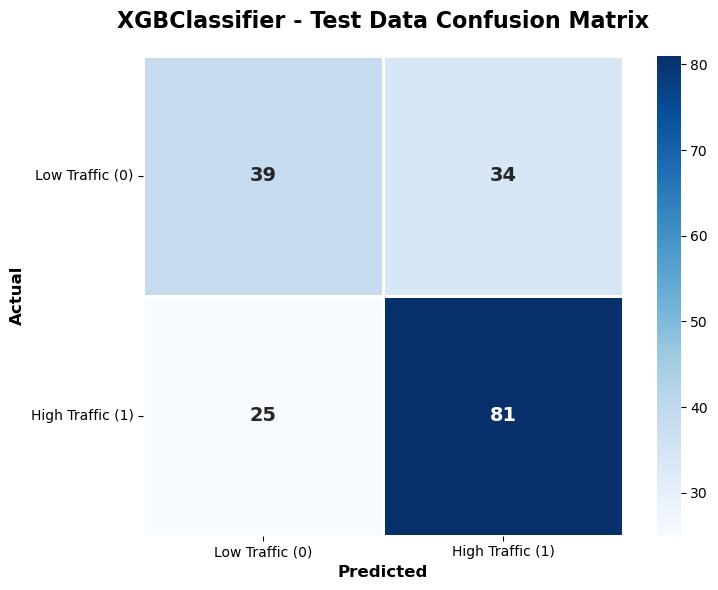

In [566]:
#Instanstiate LogisticRegression
xgb = XGBClassifier()
#Apply the function 'develop_model' to get Extreme Gradient Classifier evaluation metrics
xgb_evaluation_metrics = develop_model(xgb, X_train, X_test, y_train, y_test)


In [567]:
#Write a function to print metrics in 'evaluation_metrics' dictionary using index number
def print_metrics(evaluation_metrics):
    print("Accuracy score:", evaluation_metrics[0])
    print("Precision score:", evaluation_metrics[1])
    print("Recall score:", evaluation_metrics[2])
    print("F1 score:", evaluation_metrics[3])
    print("Confusion Matrix:",)
    print(evaluation_metrics[4])

    



In [568]:
print("GaussaianNB Train")
print_metrics(gnb_evaluation_metrics['train'])

print("GaussaianNB Test")
print_metrics(gnb_evaluation_metrics['test'])

GaussaianNB Train
Accuracy score: 0.7136871508379888
Precision score: 0.8733333333333333
Recall score: 0.6107226107226107
F1 score: 0.7187928669410151
Confusion Matrix:
[[249  38]
 [167 262]]
GaussaianNB Test
Accuracy score: 0.7262569832402235
Precision score: 0.88
Recall score: 0.6226415094339622
F1 score: 0.7292817679558011
Confusion Matrix:
[[64  9]
 [40 66]]


In [569]:

print("Logistic Regression Train")
print_metrics(logreg_evaluation_metrics['train'])

print("Logistic Regression Test")
print_metrics(logreg_evaluation_metrics['test'])

Logistic Regression Train
Accuracy score: 0.7416201117318436
Precision score: 0.7675438596491229
Recall score: 0.8158508158508159
F1 score: 0.7909604519774012
Confusion Matrix:
[[181 106]
 [ 79 350]]
Logistic Regression Test
Accuracy score: 0.7653631284916201
Precision score: 0.7857142857142857
Recall score: 0.8301886792452831
F1 score: 0.8073394495412844
Confusion Matrix:
[[49 24]
 [18 88]]


In [570]:
print("Decision Tree classifier Train")
print_metrics(ds_evaluation_metrics['train'])

print("Decision Tree classifier Train")
print_metrics(ds_evaluation_metrics['test'])

Decision Tree classifier Train
Accuracy score: 1.0
Precision score: 1.0
Recall score: 1.0
F1 score: 1.0
Confusion Matrix:
[[287   0]
 [  0 429]]
Decision Tree classifier Train
Accuracy score: 0.6201117318435754
Precision score: 0.6759259259259259
Recall score: 0.6886792452830188
F1 score: 0.6822429906542056
Confusion Matrix:
[[38 35]
 [33 73]]


In [571]:
print("Random Forest claassifier Train")
print_metrics(rf_evaluation_metrics['train'])

print("Random Forest classifier Train")
print_metrics(rf_evaluation_metrics['test'])

Random Forest claassifier Train
Accuracy score: 1.0
Precision score: 1.0
Recall score: 1.0
F1 score: 1.0
Confusion Matrix:
[[287   0]
 [  0 429]]
Random Forest classifier Train
Accuracy score: 0.6983240223463687
Precision score: 0.7166666666666667
Recall score: 0.8113207547169812
F1 score: 0.7610619469026548
Confusion Matrix:
[[39 34]
 [20 86]]


In [572]:
print("Support Vector Machine Train")
print_metrics(svm_evaluation_metrics['train'])

print("Support Vector Machine Train")
print_metrics(svm_evaluation_metrics['test'])

Support Vector Machine Train
Accuracy score: 0.5991620111731844
Precision score: 0.5991620111731844
Recall score: 1.0
F1 score: 0.7493449781659388
Confusion Matrix:
[[  0 287]
 [  0 429]]
Support Vector Machine Train
Accuracy score: 0.5921787709497207
Precision score: 0.5921787709497207
Recall score: 1.0
F1 score: 0.743859649122807
Confusion Matrix:
[[  0  73]
 [  0 106]]


In [573]:
print("LGBM classifier Train")
print_metrics(lgmb_evaluation_metrics['train'])

print("LGBM  classifier Test  ")
print_metrics(lgmb_evaluation_metrics['test'])

LGBM classifier Train
Accuracy score: 1.0
Precision score: 1.0
Recall score: 1.0
F1 score: 1.0
Confusion Matrix:
[[287   0]
 [  0 429]]
LGBM  classifier Test  
Accuracy score: 0.6759776536312849
Precision score: 0.7
Recall score: 0.7924528301886793
F1 score: 0.7433628318584071
Confusion Matrix:
[[37 36]
 [22 84]]


In [574]:
print("XGB classifier Train")
print_metrics(xgb_evaluation_metrics['train'])

print("XGB classifier Train")
print_metrics(xgb_evaluation_metrics['test'])

XGB classifier Train
Accuracy score: 1.0
Precision score: 1.0
Recall score: 1.0
F1 score: 1.0
Confusion Matrix:
[[287   0]
 [  0 429]]
XGB classifier Train
Accuracy score: 0.6703910614525139
Precision score: 0.7043478260869566
Recall score: 0.7641509433962265
F1 score: 0.7330316742081447
Confusion Matrix:
[[39 34]
 [25 81]]


## Model Comparison and Selection

The SVM model shows signs of underfitting, with a recall of 1.0 because it predicts the majority class (0) for almost all cases. Among the models tested, GaussianNB performed the best, while Logistic Regression also showed strong performance, so we proceed to hyper-tune GaussianNB to improve its results.

# Hyperparameter tuning

We'll run GridSearchCV to tune model hyperparameters (optimizing for precision). We'll try compact grids to keep runtime reasonable.


In [575]:
# Limit threads for reproducibility
import os, random
import numpy as np

random.seed(42)
np.random.seed(42)

# Parameter distribution for GuassianNB
param_grid = {
    'var_smoothing': [1e-12, 1e-11, 1e-10, 1e-9, 1e-8, 1e-7, 1e-6]
}


gaussian_search = GridSearchCV(
    estimator=GaussianNB(),
    param_grid=param_grid,
    cv=3,
    scoring='precision',
    n_jobs=1,
    verbose=1
)
gaussian_search.fit(X_train, y_train)
print(f"Best params for LogisticRegressiaon: a{gaussian_search.best_params_}")
print(f"Best precision (cav): {gaussian_search.best_score_:.4f}")
# Save tuned estimator
tuned_gaussian = gaussian_search.best_estimator_

Fitting 3 folds for each of 7 candidates, totalling 21 fits
Best params for LogisticRegressiaon: a{'var_smoothing': 1e-11}
Best precision (cav): 0.8528
Best params for LogisticRegressiaon: a{'var_smoothing': 1e-11}
Best precision (cav): 0.8528


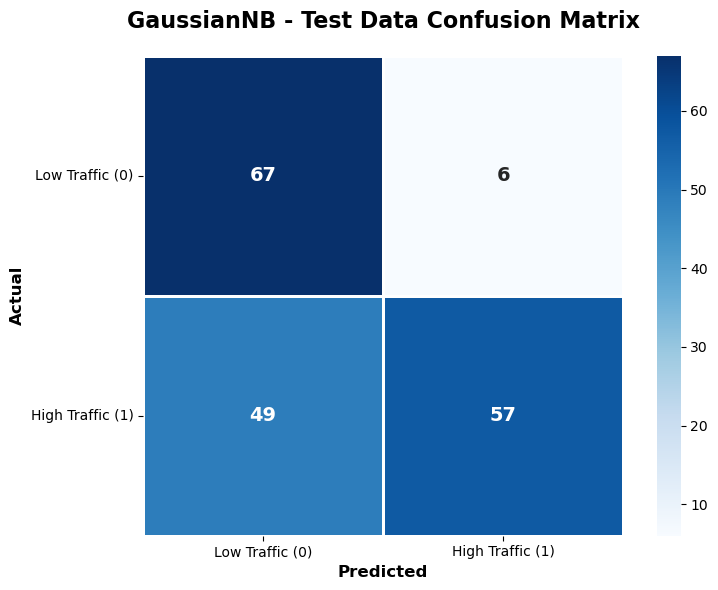


Baseline gaussian Naive Bayes Test Precision: 0.88
Tuned gaussian Naive Bayes Test Precision : 0.9047619047619048


In [576]:
# Evaluate tuned Logistic Regression and compare to baseline

try:
    tuned_evaluation = develop_model(tuned_gaussian, X_train, X_test, y_train, y_test)
    # calculate_kpi(tuned_evaluation, 'Logistic Regression (tuned)')
    print('\nBaseline gaussian Naive Bayes Test Precision:', gnb_evaluation_metrics['test'][1])
    print('Tuned gaussian Naive Bayes Test Precision :', tuned_evaluation['test'][1])
except NameError as e:
    print('tuned_gaussian not found. Please run the tuning cell first.', e)

After hyperparameter tuning, the Gaussian Naive Bayes model's precision improved from 0.88 to 0.90 on the test set. This enhancement indicates that the tuning process effectively optimized the model's performance in identifying high-traffic recipes

To measure our model's real-world usefulness, let's create a practical KPI called the "High Traffic Conversion Rate." We'll calculate this by dividing True Positives (recipes we correctly identified as high traffic) by False Positives (recipes we mistakenly tagged as high traffic). Based on our baseline model's performance, we should aim to keep this ratio at 4.0 or higher. This gives us a clear business metric: for every recipe we flag as high traffic, we want to be right at least 4 out of 5 times. It's a straightforward way to track whether our predictions are actually delivering value.


We can establish a Key Performance Indicator (KPI) by dividing True Positives (high recipes correctly classified as high) by False Positives (low recipes mistakenly classified as high) within the confusion matrix. This KPI, which we can refer to as the "High Traffic Conversion Rate," needs to be maintained at a level equal to or greater than 4.0, relying on the train and test results of our baseline model. This KPI can serve as a valuable metric for our business model, providing insights into the accuracy of high traffic predictions.

In [579]:
# KPI calculation
def calculate_kpi(model_metrics, model_name):
    kpi_train = model_metrics['train'][4]
    kpi_test = model_metrics['test'][4]
    print(f"High Traffic Conversion Rate for {model_name} train: ", kpi_train[1][1]/(kpi_train[0][1]))
    print(f"High Traffic Conversion Rate for {model_name} test: ", kpi_test[1][1]/(kpi_test[0][1]))

In [580]:
#KPI calculation for Gaussian Naive Bayes 
calculate_kpi(gnb_evaluation_metrics, "gaussian Naive Bayes Regresssion")

#KPI calculation for Logistic Regression
calculate_kpi(logreg_evaluation_metrics, "Logistic Regresssion")


#KPI calculation for Decision Tree
calculate_kpi(ds_evaluation_metrics, "Decision Tree")

#KPI calculation for Random Forest
calculate_kpi(rf_evaluation_metrics, "Random Forest")

#KPI calculation for Support Vector Machine
calculate_kpi(svm_evaluation_metrics, "Support Vector Machine")

#KPI calculation for Light Gradient Boosting Machine(LGBM)
calculate_kpi(lgmb_evaluation_metrics, "LGBM")

#KPI calculation for Extreme Gradient Boosting(XGB)
calculate_kpi(xgb_evaluation_metrics, "XGB")
print

High Traffic Conversion Rate for gaussian Naive Bayes Regresssion train:  6.894736842105263
High Traffic Conversion Rate for gaussian Naive Bayes Regresssion test:  7.333333333333333
High Traffic Conversion Rate for Logistic Regresssion train:  3.30188679245283
High Traffic Conversion Rate for Logistic Regresssion test:  3.6666666666666665
High Traffic Conversion Rate for Decision Tree train:  inf
High Traffic Conversion Rate for Decision Tree test:  2.085714285714286
High Traffic Conversion Rate for Random Forest train:  inf
High Traffic Conversion Rate for Random Forest test:  2.5294117647058822
High Traffic Conversion Rate for Support Vector Machine train:  1.494773519163763
High Traffic Conversion Rate for Support Vector Machine test:  1.452054794520548
High Traffic Conversion Rate for LGBM train:  inf
High Traffic Conversion Rate for LGBM test:  2.3333333333333335
High Traffic Conversion Rate for XGB train:  inf
High Traffic Conversion Rate for XGB test:  2.3823529411764706


C:\Users\Mariam\AppData\Local\Temp\ipykernel_11296\459368362.py:5: RuntimeWarning: divide by zero encountered in scalar divide
  print(f"High Traffic Conversion Rate for {model_name} train: ", kpi_train[1][1]/(kpi_train[0][1]))


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

 GaussianNB exceeds the KPI on both train and test, showing reliable performance. Logistic Regression also meets the KPI, slightly below GaussianNB. Decision Tree, Random Forest, LGBM, and XGBoost overfit, with high train but lower test KPIs. SVM fails to meet the KPI, predicting mostly the majority class.

In summary, I developed and evaluated multiple models to achieve our goal. Among these, the Gaussian Naive Bayes model proved to be the best performer, making it the ideal choice for predicting high-traffic recipes with an precision of around 90%. From a business perspective, misclassifying a high-traffic recipe as low traffic is a more critical error than the reverse. Therefore, My main focus is on model precision, since failing to identify a popular recipe can cause significant business losses.  I also introduced a custom Key Performance Indicator (KPI) called the "High Traffic Conversion Rate," based on the results of our baseline model. This KPI helps me compare the effectiveness of different models. My exploratory analysis revealed that certain recipe categories consistently attract either high or low traffic. Recipes in the "Vegetable," "Potato," or "Pork" categories tend to drive high traffic and are recommended for featuring on the website. In contrast, "Beverages" recipes typically attract low traffic and are less suitable for the platform.
'''